# Cookie Cats: Should the First Gate Be at Level 30 or Level 40?

**Cookie Cats** is a casual match-3 mobile puzzle game. As players progress, they hit **gates** that force a pause: wait, or pay to continue. Gates are a core lever for both **pacing** (preventing burnout) and **monetization**.

The team ran an A/B test moving the first gate from **level 30 (control)** to **level 40 (treatment)**. Each new player was randomly assigned to one version.

**Question:** Does moving the gate to level 40 change player retention and engagement, and should we ship it?

| Metric | Role | Definition |
|---|---|---|
| **D7 retention** | Primary | Player came back and played 7 days after install |
| D1 retention | Secondary | Player came back and played 1 day after install |
| Game rounds | Secondary | Rounds played in the first 14 days |

**Hypothesis.** H0: no difference between versions. H1: retention differs between gate_30 and gate_40. Significance level α = 0.05, two-sided.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"gate_30": "#2a6fdb", "gate_40": "#e8833a"}
rng = np.random.default_rng(42)
Path = __import__("pathlib").Path
Path("figures").mkdir(exist_ok=True)

df = pd.read_csv("data/cookie_cats.csv")
df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## 1. Data quality checks

In [2]:
print(f"Rows: {len(df):,} | Unique users: {df.userid.nunique():,} | Missing values: {df.isna().sum().sum()}")
df.groupby("version").size().rename("players").to_frame()

Rows: 90,189 | Unique users: 90,189 | Missing values: 0


,players
version,
gate_30,44700
gate_40,45489


### Sample Ratio Mismatch (SRM) check

With 50/50 random assignment, the groups should be about equal in size. A chi-square goodness-of-fit test tells us if the split is suspiciously uneven. An SRM can mean an assignment or logging bug, and that can bias every result downstream.

In [3]:
counts = df.groupby("version").size()
srm = stats.chisquare(counts.values)
print(f"gate_30: {counts['gate_30']:,} | gate_40: {counts['gate_40']:,} | share gate_40: {counts['gate_40']/counts.sum():.2%}")
print(f"SRM chi-square p-value: {srm.pvalue:.4f}")

gate_30: 44,700 | gate_40: 45,489 | share gate_40: 50.44%
SRM chi-square p-value: 0.0086


**Finding:** p ≈ 0.009 < 0.05, so the split is **not** a clean 50/50 (49.6% / 50.4%). The gap is small, but in a real team I would raise this with engineering before trusting the results: check the assignment logic and event logging. Here we can't investigate further, so we go on with the analysis and **list this as a caveat** in the final recommendation.

## 2. Engagement distribution and outliers

In [4]:
df.sum_gamerounds.describe(percentiles=[.5, .9, .99, .999]).round(1)

count    90189.0
mean        51.9
std        195.1
min          0.0
50%         16.0
90%        134.0
99%        493.0
99.9%     1073.6
max      49854.0
Name: sum_gamerounds, dtype: float64

In [5]:
df.nlargest(3, "sum_gamerounds")

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False


One player logged **49,854 rounds** in 14 days (~3,500 per day). The next highest is 2,961. This is almost certainly a bot or a logging error, so we remove this single row. About 4.4% of players never played a single round, which is normal for mobile installs.

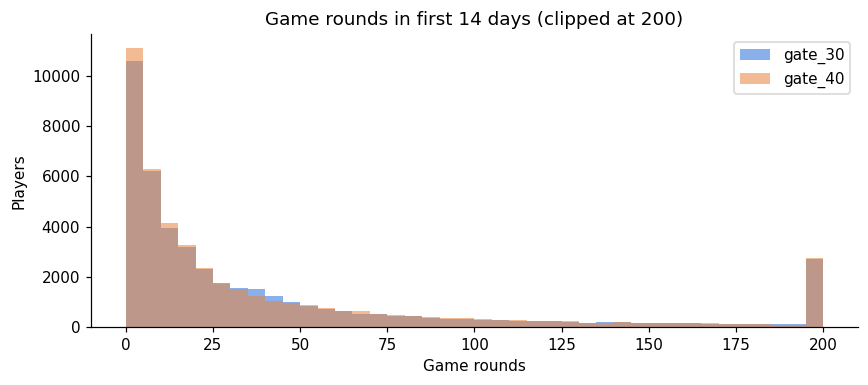

Players remaining: 90,188


In [6]:
df = df[df.sum_gamerounds < 49854].copy()

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(0, 201, 5)
for v, g in df.groupby("version"):
    ax.hist(g.sum_gamerounds.clip(upper=200), bins=bins, alpha=.55, label=v, color=COLORS[v])
ax.set(title="Game rounds in first 14 days (clipped at 200)", xlabel="Game rounds", ylabel="Players")
ax.legend(); plt.tight_layout(); plt.savefig("figures/rounds_distribution.png"); plt.show()
print(f"Players remaining: {len(df):,}")

Engagement is heavily right-skewed: most players drop off early, and a small group of highly engaged players plays hundreds of rounds. A mean comparison would be distorted by these heavy players, so we compare engagement with a non-parametric test.

## 3. Retention: frequentist test

In [7]:
def compare(metric):
    g = df.groupby("version")[metric].agg(["sum", "count", "mean"])
    z, p = proportions_ztest(g["sum"].values, g["count"].values)
    lo, hi = confint_proportions_2indep(g.loc["gate_40", "sum"], g.loc["gate_40", "count"],
                                        g.loc["gate_30", "sum"], g.loc["gate_30", "count"])
    diff = g.loc["gate_40", "mean"] - g.loc["gate_30", "mean"]
    return {"metric": metric, "gate_30": g.loc["gate_30", "mean"], "gate_40": g.loc["gate_40", "mean"],
            "diff_pp": 100 * diff, "ci_low_pp": 100 * lo, "ci_high_pp": 100 * hi,
            "relative_change": diff / g.loc["gate_30", "mean"], "p_value": p}

results = pd.DataFrame([compare("retention_1"), compare("retention_7")]).set_index("metric")
results.style.format({"gate_30": "{:.2%}", "gate_40": "{:.2%}", "diff_pp": "{:+.2f}", "ci_low_pp": "{:+.2f}",
                      "ci_high_pp": "{:+.2f}", "relative_change": "{:+.1%}", "p_value": "{:.4f}"})

,gate_30,gate_40,diff_pp,ci_low_pp,ci_high_pp,relative_change,p_value
metric,,,,,,,
retention_1,44.82%,44.23%,-0.59,-1.24,+0.06,-1.3%,0.0739
retention_7,19.02%,18.20%,-0.82,-1.33,-0.31,-4.3%,0.0016


- **D1 retention:** 44.82% → 44.23% (−0.59 pp). p ≈ 0.07, **not statistically significant**. The 95% CI includes zero.
- **D7 retention:** 19.02% → 18.20% (**−0.82 pp, −4.3% relative**). p ≈ 0.002, **statistically significant**. The whole 95% CI is below zero (−1.33 to −0.31 pp).

## 4. Retention: bootstrap

As a robustness check, we resample each group 2,000 times and look at the distribution of the retention difference. This makes no normality assumption and shows the uncertainty directly.

retention_1: P(gate_30 > gate_40) = 96.5%
retention_7: P(gate_30 > gate_40) = 100.0%


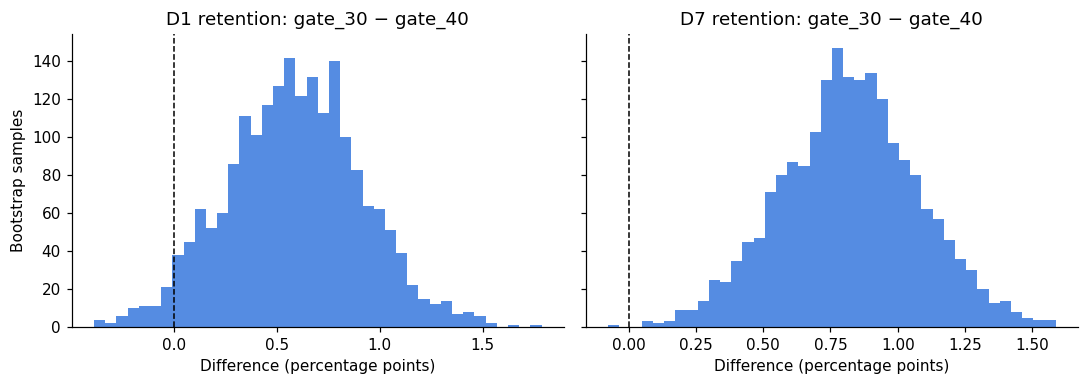

In [8]:
def bootstrap_diff(metric, n=2000):
    a = df.loc[df.version == "gate_30", metric].values
    b = df.loc[df.version == "gate_40", metric].values
    return np.array([rng.choice(a, a.size).mean() - rng.choice(b, b.size).mean() for _ in range(n)])

boot = {m: bootstrap_diff(m) for m in ["retention_1", "retention_7"]}

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for ax, (m, d) in zip(axes, boot.items()):
    ax.hist(100 * d, bins=40, color="#2a6fdb", alpha=.8)
    ax.axvline(0, color="black", lw=1, ls="--")
    ax.set(title=f"{m.replace('retention_', 'D')} retention: gate_30 − gate_40",
           xlabel="Difference (percentage points)")
    print(f"{m}: P(gate_30 > gate_40) = {(d > 0).mean():.1%}")
axes[0].set_ylabel("Bootstrap samples")
plt.tight_layout(); plt.savefig("figures/bootstrap_retention.png"); plt.show()

The bootstrap agrees with the z-test. Gate 30 has higher D7 retention in **more than 99.9%** of resamples, and higher D1 retention in about 96%. That makes D1 suggestive but not conclusive.

## 5. Engagement: game rounds

In [9]:
eng = df.groupby("version").sum_gamerounds.agg(["mean", "median"])
mwu = stats.mannwhitneyu(df.loc[df.version == "gate_30", "sum_gamerounds"],
                         df.loc[df.version == "gate_40", "sum_gamerounds"])
print(eng.round(1)); print(f"\nMann-Whitney U p-value: {mwu.pvalue:.4f}")

         mean  median
version              
gate_30  51.3    17.0
gate_40  51.3    16.0

Mann-Whitney U p-value: 0.0509


Means are almost the same (51.3 vs 51.3) and medians are 17 vs 16. The Mann-Whitney test is borderline (p ≈ 0.05). **Total engagement does not move in a meaningful way.** The main effect is on players coming back after a week, not on how much they play.

## 6. Segment: players who actually reached the gate

Players who never reach level 30 can't be affected by the gate at all, and they dilute the effect. As a proxy for "reached the gate", we look at players with **30+ rounds**. Caveat: rounds ≠ levels, because players can replay levels.

In [10]:
seg = df[df.sum_gamerounds >= 30]
seg_summary = seg.groupby("version").agg(players=("userid", "size"), D1=("retention_1", "mean"), D7=("retention_7", "mean"))
g = seg.groupby("version").retention_7.agg(["sum", "count"])
print(seg_summary.round(4))
print(f"\nD7 z-test p-value (30+ rounds): {proportions_ztest(g['sum'].values, g['count'].values)[1]:.4f}")

         players      D1      D7
version                         
gate_30    16655  0.8010  0.4387
gate_40    16613  0.8018  0.4300

D7 z-test p-value (30+ rounds): 0.1093


Among engaged players, D7 retention is 43.87% for gate_30 vs 43.00% for gate_40. The direction is the same (−0.87 pp), but with this smaller sample the difference is not significant on its own (p ≈ 0.11). The effect is **consistent** across segments, but the full-population test is the decisive one.

## 7. Decision and business impact

### Recommendation: **keep the gate at level 30. Do not ship gate_40.**

- The primary metric, **D7 retention, drops by 0.82 pp (−4.3% relative)**. The result is statistically significant and confirmed by the bootstrap.
- D1 retention and total rounds show no meaningful gain that could offset this.
- **Scale:** for every **1M new installs**, gate_40 would mean about **8,200 fewer players still active on day 7**. That is a smaller audience for LiveOps events, ads, and IAP, and it compounds into lower LTV.

### Why might an earlier gate retain better?
A likely explanation is **hedonic adaptation**. A forced break at level 30 makes players stop before they burn out, so the game stays enjoyable and they come back. Pushing the gate to 40 lets players binge longer, and more of them get bored before day 7.

### Caveats
1. **Sample ratio mismatch** (p ≈ 0.009): the 49.6/50.4 split should be checked for assignment or logging issues before a final ship decision.
2. **No revenue data:** the gate also drives monetization (pay to skip). A complete decision would include conversion, ARPDAU, and LTV per variant.
3. **Rounds are a proxy for level progress.**

### What I'd test next
- **Gate at level 25 vs 30**, to see whether an even earlier break improves retention further.
- **Gate format:** wait timer length, and a rewarded-ad option to unlock vs. IAP-only. This would measure the retention vs. monetization trade-off directly.
- Add **guardrail metrics** (session length, D30 retention, IAP conversion) to future gate tests.